# Análisis Fronteras Canceladas
## Descripción Base de Datos

Esta base de datos consolida las publicaciones mensuales de **cancelación o inicio de Plan de Normalización (PN)** de fronteras comerciales
por acumulación de fallas (Anexo 11 del Código de Medida, adicionado a la Resolución CREG 038 de 2014 por la Resolución CREG 033 de 2019), entre **enero y octubre de 2026**. Para cada falla se registra la frontera (código SIC),
el tipo de falla, la fecha de reporte, el tipo de frontera y la decisión tomada.

 **Estructura de los datos**:
   - Los datos son **estructurados**, organizados en tablas con filas y columnas definidas.

 **Formato del archivo**:
   - Archivo **Excel (.xlsx)** con tres hojas: `Consolidado` (detalle de fallas), `Resumen` (totales por mes) e `Historico_2022`.

 **Parser**:
   - No se necesita un parser especializado; se carga directamente con `pd.read_excel()` indicando la hoja.

 **Tipología de las variables**:
   - **Cualitativas**:
     - **Nominales**: `CódigoSIC`, `Tipo de Falla`, `Tipo de Frontera` y la decisión (`Cancela` / `PN`).
     - **Ordinales**: `Mes publicación` (periodo mensual con orden en el tiempo).
   - **Cuantitativas**:
     - **Continuas**: `Fecha de Reporte` (fecha y hora), de la cual se deriva la antigüedad de la falla en días (**discreta**).

**Nota:** no se recibió el archivo de **2026-02**, por lo que ese mes aparece vacío en las gráficas.

## Librerias

In [1]:
import pandas as pd
import numpy  as np
import seaborn as sns
import matplotlib.pyplot as plt

## Leer Datos

In [2]:


ruta = r"C:\Users\santi\Escritorio\Data analitics\introduccion a ciencia de datos\fronteras\Consolidado_CancelacionFallasFC_2026.xlsx"

df = pd.read_excel(ruta, sheet_name="Consolidado")
resumen = pd.read_excel(ruta, sheet_name="Resumen")
historico = pd.read_excel(ruta, sheet_name="Historico_2022")

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 424 entries, 0 to 423
Data columns (total 6 columns):
 #   Column                                                                            Non-Null Count  Dtype         
---  ------                                                                            --------------  -----         
 0   Mes publicación                                                                   424 non-null    str           
 1   CódigoSIC                                                                         424 non-null    str           
 2   Tipo de Falla                                                                     424 non-null    str           
 3   Fecha de Reporte                                                                  424 non-null    datetime64[us]
 4   Tipo de Frontera                                                                  424 non-null    str           
 5   ¿Se Cancela o inicia Plan de Normalización -PN- (Anexo 11 del código de medi

### Limpieza
Se renombran las columnas a nombres cortos, el mes se convierte a periodo mensual y se quita el prefijo "Tipo " de la frontera.

In [4]:
# Renombrar columnas
df.columns = ["Mes", "Frontera", "Tipo_Falla", "Fecha_Reporte", "Tipo_Frontera", "Decision"]

# Convertir el mes a periodo y limpiar textos
df["Mes"] = pd.PeriodIndex(df["Mes"], freq="M")
df["Tipo_Frontera"] = df["Tipo_Frontera"].str.replace("Tipo ", "", regex=False)

# Lista de todos los meses del periodo (incluye 2026-02 que no tiene datos)
meses = pd.period_range(df["Mes"].min(), df["Mes"].max(), freq="M")
etiquetas = [m.strftime("%b-%y") for m in meses]

# Colores usados en todas las graficas
azul, naranja, verde, morado = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
colores = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
sns.set(style="whitegrid")

df.head()

,Mes,Frontera,Tipo_Falla,Fecha_Reporte,Tipo_Frontera,Decision
0,2026-01,Frt23843,Falla Dispositivos de interfaz de comunicación,2025-02-06 17:47:58,No Regulado,Cancela
1,2026-01,Frt23843,Falla Dispositivos de interfaz de comunicación,2025-09-12 14:47:07,No Regulado,Cancela
2,2026-01,Frt23843,Falla Contador Principal,2025-12-28 16:44:01,No Regulado,Cancela
3,2026-01,Frt55810,Falla Contador Principal,2025-09-29 10:26:16,No Regulado,Cancela
4,2026-01,Frt55810,Falla Contador Principal,2025-10-30 15:00:23,No Regulado,Cancela


# EDA - Análisis mes a mes

## Resumen por mes

In [5]:
# Agrupar por mes y calcular indicadores
resumen_mes = df.groupby("Mes").agg(
    Fallas=("Frontera", "size"),
    Cancela=("Decision", lambda s: (s == "Cancela").sum()),
    PN=("Decision", lambda s: (s == "PN").sum()),
    Fronteras=("Frontera", "nunique"),
).reindex(meses)

resumen_mes["% PN"] = (resumen_mes["PN"] / resumen_mes["Fallas"] * 100).round(1)
resumen_mes["Fallas por frontera"] = (resumen_mes["Fallas"] / resumen_mes["Fronteras"]).round(2)
resumen_mes["Variacion vs mes anterior (%)"] = (resumen_mes["Fallas"].pct_change(fill_method=None) * 100).round(1)
resumen_mes

,Fallas,Cancela,PN,Fronteras,% PN,Fallas por frontera,Variacion vs mes anterior (%)
2026-01,9.0,6.0,3.0,3.0,33.3,3.00,NaN
2026-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-03,64.0,52.0,12.0,20.0,18.8,3.20,NaN
2026-04,29.0,23.0,6.0,9.0,20.7,3.22,-54.7
2026-05,33.0,27.0,6.0,11.0,18.2,3.00,13.8
2026-06,89.0,36.0,53.0,22.0,59.6,4.05,169.7
2026-07,78.0,23.0,55.0,19.0,70.5,4.11,-12.4
2026-08,57.0,32.0,25.0,14.0,43.9,4.07,-26.9
2026-09,21.0,9.0,12.0,7.0,57.1,3.00,-63.2
2026-10,44.0,27.0,17.0,13.0,38.6,3.38,109.5


## Fallas por mes: Cancela vs Plan de Normalización

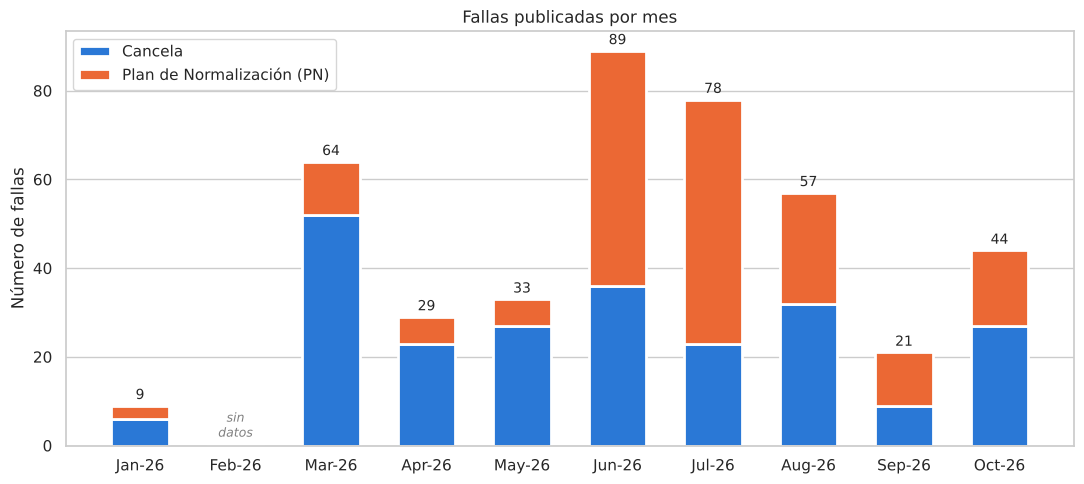

In [6]:
x = np.arange(len(meses))
cancela = resumen_mes["Cancela"].fillna(0)
pn = resumen_mes["PN"].fillna(0)

plt.figure(figsize=(11, 5))
plt.bar(x, cancela, color=azul, label="Cancela", width=0.6, edgecolor="white", linewidth=2)
plt.bar(x, pn, bottom=cancela, color=naranja, label="Plan de Normalización (PN)", width=0.6, edgecolor="white", linewidth=2)

# Total encima de cada barra
for i, total in enumerate(resumen_mes["Fallas"]):
    if np.isnan(total):
        plt.text(i, 2, "sin\ndatos", ha="center", fontsize=9, style="italic", color="gray")
    else:
        plt.text(i, total + 1.5, int(total), ha="center", fontsize=10)

plt.xticks(x, etiquetas)
plt.ylabel("Número de fallas")
plt.title("Fallas publicadas por mes")
plt.legend(loc="upper left")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

Se publicaron **424 fallas** en 9 meses (promedio de 47 por mes). Hay dos picos claros: **marzo (64)**, el primer mes después del vacío de febrero
y que posiblemente acumula fallas de ese mes, y **junio–julio (89 y 78)**, los meses más altos del año. Desde agosto el volumen baja,
con un mínimo en **septiembre (21)** y una nueva subida en **octubre (44)**.

## Porcentaje de fallas que inician Plan de Normalización

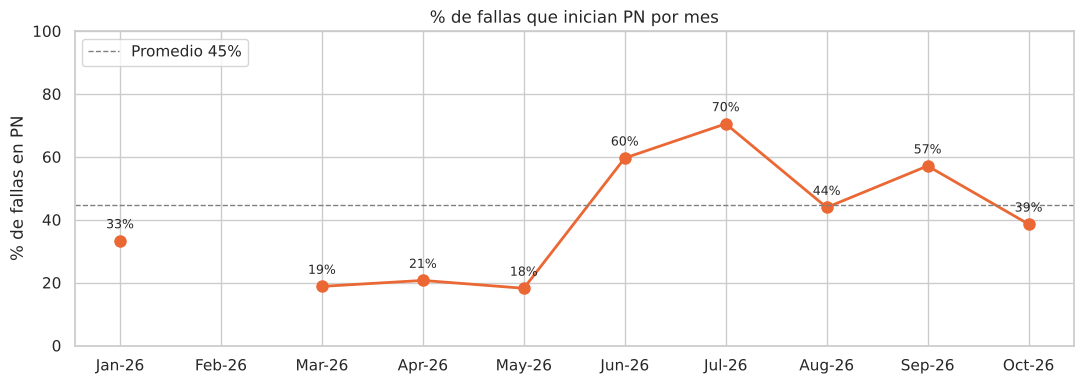

In [7]:
porcentaje_pn = resumen_mes["% PN"]
promedio_pn = (df["Decision"] == "PN").mean() * 100

plt.figure(figsize=(11, 4))
plt.plot(x, porcentaje_pn, color=naranja, marker="o", markersize=8, linewidth=2)
for i, v in enumerate(porcentaje_pn):
    if not np.isnan(v):
        plt.text(i, v + 4, f"{v:.0f}%", ha="center", fontsize=9)

plt.axhline(promedio_pn, color="gray", linestyle="--", linewidth=1, label=f"Promedio {promedio_pn:.0f}%")
plt.xticks(x, etiquetas)
plt.ylim(0, 100)
plt.ylabel("% de fallas en PN")
plt.title("% de fallas que inician PN por mes")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

En el primer semestre predomina la **cancelación** (PN entre 18% y 33%), pero en **junio y julio** el comportamiento se invierte y el **60%–71%**
de las fallas pasa a **Plan de Normalización**. A partir de agosto el porcentaje vuelve a bajar hacia el promedio general (45%).

## Tipo de falla por mes

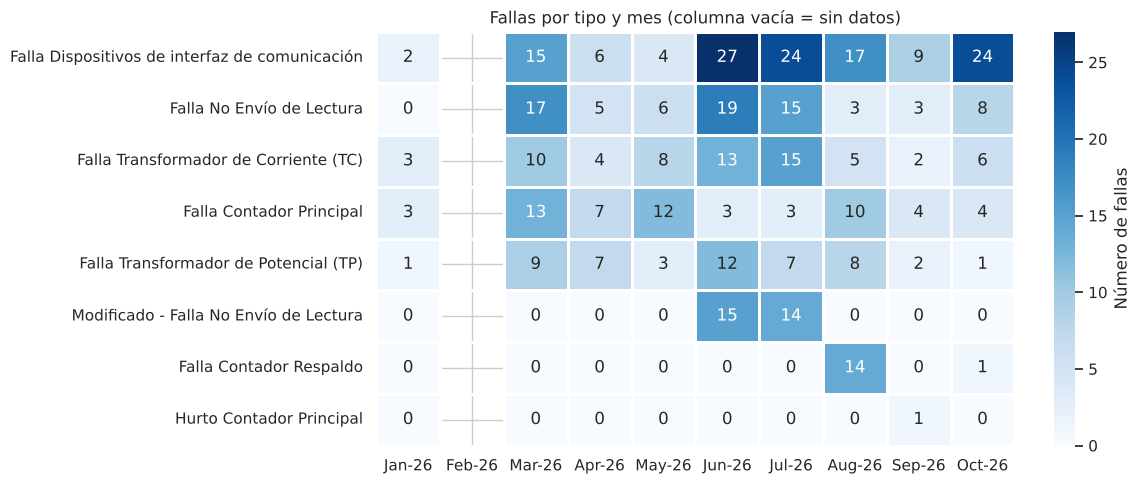

In [8]:
# Tabla cruzada tipo de falla vs mes
falla_mes = pd.crosstab(df["Tipo_Falla"], df["Mes"]).reindex(columns=meses)
falla_mes = falla_mes.loc[falla_mes.sum(axis=1).sort_values(ascending=False).index]
falla_mes.columns = etiquetas

plt.figure(figsize=(12, 5))
sns.heatmap(falla_mes, annot=True, fmt=".0f", cmap="Blues", linewidths=2,
            mask=falla_mes.isna(), cbar_kws={"label": "Número de fallas"})
plt.title("Fallas por tipo y mes (columna vacía = sin datos)")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

- **Falla de dispositivos de interfaz de comunicación** es la más frecuente (128, el 30%), y es la que más crece en junio, julio y octubre (24–27 por mes).
- **No envío de lectura** (incluida la versión "Modificado") suma 105 casos y se concentra en marzo, junio y julio; la categoría "Modificado" solo aparece en **junio y julio**.
- **Falla contador respaldo** aparece casi únicamente en **agosto (14)**, un caso puntual.
- Solo hay **un hurto** de contador principal (septiembre).

## Total de fallas por tipo y decisión

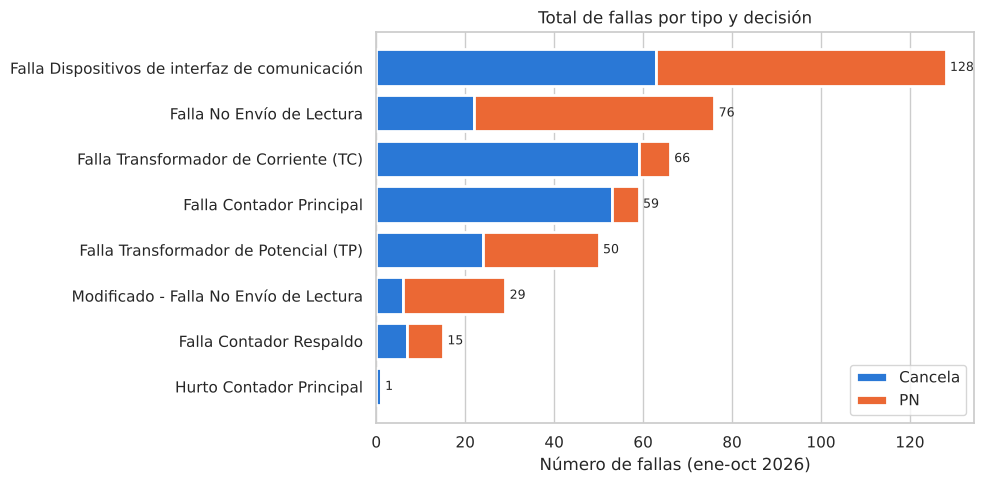

Decision,Cancela,PN,Total,% PN
Tipo_Falla,,,,
Falla Dispositivos de interfaz de comunicación,63,65,128,50.8
Falla No Envío de Lectura,22,54,76,71.1
Falla Transformador de Corriente (TC),59,7,66,10.6
Falla Contador Principal,53,6,59,10.2
Falla Transformador de Potencial (TP),24,26,50,52.0
Modificado - Falla No Envío de Lectura,6,23,29,79.3
Falla Contador Respaldo,7,8,15,53.3
Hurto Contador Principal,1,0,1,0.0


In [9]:
tipo_decision = pd.crosstab(df["Tipo_Falla"], df["Decision"])
tipo_decision["Total"] = tipo_decision.sum(axis=1)
tipo_decision["% PN"] = (tipo_decision["PN"] / tipo_decision["Total"] * 100).round(1)
tipo_decision = tipo_decision.sort_values("Total")

plt.figure(figsize=(10, 5))
plt.barh(tipo_decision.index, tipo_decision["Cancela"], color=azul, label="Cancela", edgecolor="white", linewidth=2)
plt.barh(tipo_decision.index, tipo_decision["PN"], left=tipo_decision["Cancela"], color=naranja, label="PN", edgecolor="white", linewidth=2)
for i, total in enumerate(tipo_decision["Total"]):
    plt.text(total + 1, i, total, va="center", fontsize=9)
plt.xlabel("Número de fallas (ene-oct 2026)")
plt.title("Total de fallas por tipo y decisión")
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

tipo_decision.sort_values("Total", ascending=False)

Las fallas de **contador principal** y **transformador de corriente (TC)** terminan casi siempre en **cancelación** (~90%),
mientras que el **no envío de lectura** termina mayormente en **PN** (71%–79%). Esto no depende de la falla en sí, sino del tipo de frontera
donde ocurre, como se ve en la siguiente sección.

## Tipo de frontera por mes

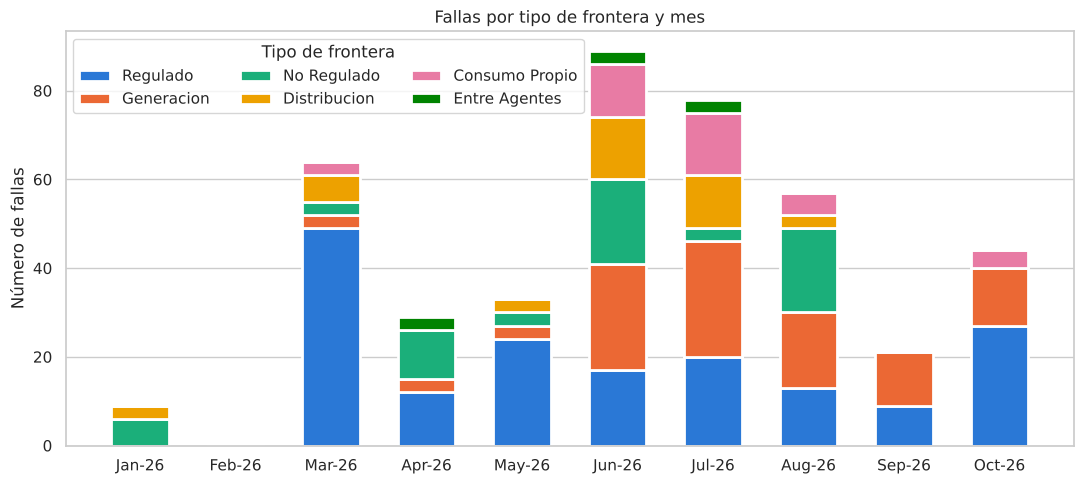

In [10]:
frontera_mes = pd.crosstab(df["Mes"], df["Tipo_Frontera"]).reindex(meses).fillna(0)
orden = frontera_mes.sum().sort_values(ascending=False).index
frontera_mes = frontera_mes[orden]

plt.figure(figsize=(11, 5))
base = np.zeros(len(meses))
for color, tipo in zip(colores, orden):
    plt.bar(x, frontera_mes[tipo], bottom=base, color=color, label=tipo, width=0.6, edgecolor="white", linewidth=2)
    base += frontera_mes[tipo].values
plt.xticks(x, etiquetas)
plt.ylabel("Número de fallas")
plt.title("Fallas por tipo de frontera y mes")
plt.legend(title="Tipo de frontera", ncol=3, loc="upper left")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

- **Regulado** es el tipo con más fallas (171) y domina **marzo (49)** y **octubre (27)**.
- **Generación** (101) es casi nula al inicio del año y crece desde junio (24–26 por mes), siendo el tipo principal en **junio, julio y agosto**.
- **Consumo Propio** y **Distribución** aparecen con fuerza en **junio y julio**, lo que explica el aumento de PN en esos meses.

## Decisión según el tipo de frontera

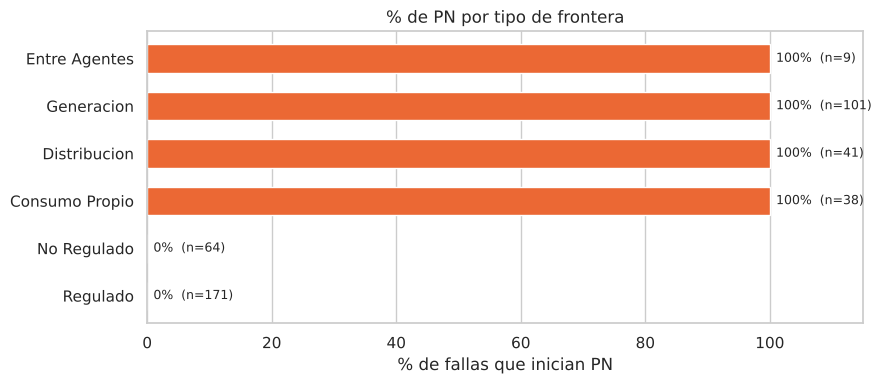

Decision,Cancela,PN,Total,% PN
Tipo_Frontera,,,,
Regulado,171,0,171,0.0
Generacion,0,101,101,100.0
No Regulado,64,0,64,0.0
Distribucion,0,41,41,100.0
Consumo Propio,0,38,38,100.0
Entre Agentes,0,9,9,100.0


In [11]:
frontera_decision = pd.crosstab(df["Tipo_Frontera"], df["Decision"])
frontera_decision["Total"] = frontera_decision.sum(axis=1)
frontera_decision["% PN"] = (frontera_decision["PN"] / frontera_decision["Total"] * 100).round(1)
frontera_decision = frontera_decision.sort_values("% PN")

plt.figure(figsize=(9, 4))
plt.barh(frontera_decision.index, frontera_decision["% PN"], color=naranja, height=0.6)
for i, (v, n) in enumerate(zip(frontera_decision["% PN"], frontera_decision["Total"])):
    plt.text(v + 1, i, f"{v:.0f}%  (n={n})", va="center", fontsize=9)
plt.xlim(0, 115)
plt.xlabel("% de fallas que inician PN")
plt.title("% de PN por tipo de frontera")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

frontera_decision.sort_values("Total", ascending=False)

La decisión está **totalmente determinada por el tipo de frontera**:
- **Regulado** y **No Regulado** (fronteras de usuarios) → **100% Cancela**.
- **Generación, Distribución, Consumo Propio y Entre Agentes** → **100% Plan de Normalización**.

Esto no es casualidad: es lo que establece el **Anexo 11 del Código de Medida (Resolución CREG 033 de 2019)**. Las fronteras de generación, distribución, comercialización entre agentes y las conectadas al STN no se cancelan por falla o hurto: el representante tiene 30 días para formular un plan de normalización de máximo 6 meses. Las fronteras de comercialización de usuarios no conectadas al STN sí se cancelan.

Por eso los meses con más fronteras de generación y distribución (junio y julio) son los que tienen más PN.

## Cifras por frontera
Cada fila de la base es una **falla**, pero la decisión (cancelar o PN) se toma sobre la **frontera**. Una frontera con 19 fallas pesa 19 veces si se cuenta por falla, así que aquí se resumen los indicadores principales contando cada frontera una sola vez.

In [12]:
# Fronteras con al menos una falla de comunicación
es_comunicacion = df["Tipo_Falla"].str.contains("comunicación")
fronteras_com = df.loc[es_comunicacion, "Frontera"].unique()

# Decisión por frontera (cada frontera tiene una sola decisión en la base)
decision_frontera = df.groupby("Frontera")["Decision"].first()

print("Fronteras distintas:", df["Frontera"].nunique())
print("Fronteras con falla de comunicación:", len(fronteras_com))
print("\nDecisión por frontera:")
print(decision_frontera.value_counts().to_string())
print("\nCanceladas con falla de comunicación:",
      decision_frontera[decision_frontera.index.isin(fronteras_com)].eq("Cancela").sum())

# Fallas por frontera en cada publicación mensual
fallas_publicacion = df.groupby(["Mes", "Frontera"]).size()
print("\nPublicaciones frontera-mes:", len(fallas_publicacion))
print("Distribución de fallas por publicación:")
print(fallas_publicacion.value_counts().sort_index().to_string())

# Fallas de comunicación por mes
print("\nFallas de comunicación por mes:")
print(df[es_comunicacion].groupby("Mes").size().reindex(meses).to_string())

Fronteras distintas: 100
Fronteras con falla de comunicación: 46

Decisión por frontera:
Decision
Cancela    70
PN         30

Canceladas con falla de comunicación: 28

Publicaciones frontera-mes: 118
Distribución de fallas por publicación:
2      1
3     85
4     16
5      7
6      5
9      2
10     2

Fallas de comunicación por mes:
2026-01     2.0
2026-02     NaN
2026-03    15.0
2026-04     6.0
2026-05     4.0
2026-06    27.0
2026-07    24.0
2026-08    17.0
2026-09     9.0
2026-10    24.0
Freq: M


- **46 de las 100 fronteras** tuvieron al menos una falla de dispositivos de interfaz de comunicación.
- Contando por frontera, **70 se cancelaron y 30 entraron a PN** (por falla el reparto es 55% / 45%, porque las fronteras en PN acumulan más fallas).
- **28 de las 70 fronteras canceladas** tenían al menos una falla de comunicación.
- En **85 de las 118 publicaciones** frontera-mes la frontera aparece con **exactamente 3 fallas**. El artículo 36 de la CREG 038 de 2014 (Tabla 5) admite como máximo 4, 4, 3 y 2 fallas en 12 meses según la antigüedad de la frontera (año 1, 2, 3 y 4 en adelante), y cuenta por igual las fallas del medidor principal, el de respaldo, los transformadores de medida y los dispositivos de interfaz de comunicación. Tres fallas superan el límite de una frontera con 4 años o más, lo que es consistente con que la mayoría de las fronteras publicadas tenga esa antigüedad. La base no trae la fecha de registro de cada frontera, así que esto queda como hipótesis.
- Las fallas de comunicación vuelven a subir en **octubre (24)**, cerca del máximo de **junio (27)**.

## Fronteras nuevas vs recurrentes por mes

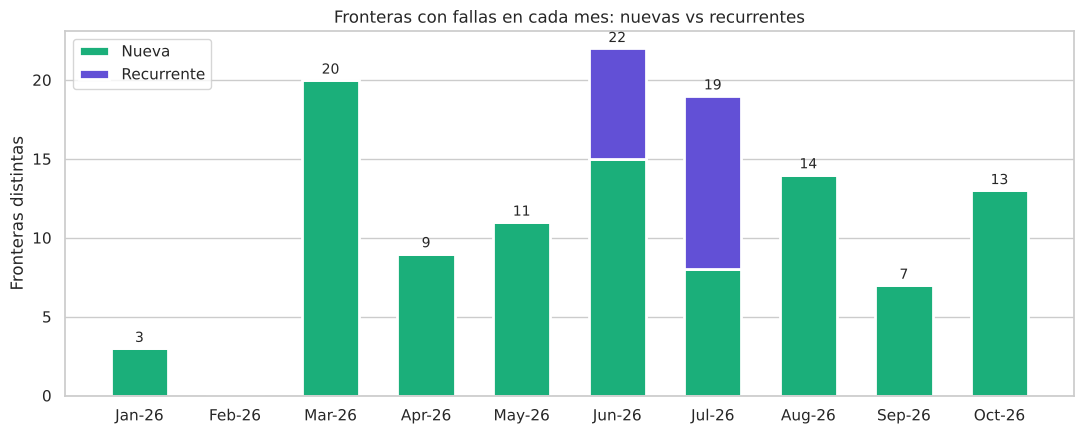

Condicion,Nueva,Recurrente
2026-01,3,0
2026-02,0,0
2026-03,20,0
2026-04,9,0
2026-05,11,0
2026-06,15,7
2026-07,8,11
2026-08,14,0
2026-09,7,0
2026-10,13,0


In [13]:
# Primer mes en que aparece cada frontera
primer_mes = df.groupby("Frontera")["Mes"].min()

frontera_por_mes = df[["Mes", "Frontera"]].drop_duplicates()
frontera_por_mes["Condicion"] = np.where(
    frontera_por_mes["Frontera"].map(primer_mes) == frontera_por_mes["Mes"], "Nueva", "Recurrente")
nuevas_recurrentes = pd.crosstab(frontera_por_mes["Mes"], frontera_por_mes["Condicion"]).reindex(meses).fillna(0)

plt.figure(figsize=(11, 4.5))
plt.bar(x, nuevas_recurrentes["Nueva"], color=verde, label="Nueva", width=0.6, edgecolor="white", linewidth=2)
plt.bar(x, nuevas_recurrentes["Recurrente"], bottom=nuevas_recurrentes["Nueva"], color=morado,
        label="Recurrente", width=0.6, edgecolor="white", linewidth=2)
for i, total in enumerate(nuevas_recurrentes.sum(axis=1)):
    if total > 0:
        plt.text(i, total + 0.4, int(total), ha="center", fontsize=10)
plt.xticks(x, etiquetas)
plt.ylabel("Fronteras distintas")
plt.title("Fronteras con fallas en cada mes: nuevas vs recurrentes")
plt.legend(loc="upper left")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

nuevas_recurrentes.astype(int)

Hay **100 fronteras distintas**. Casi todas aparecen por primera vez en el mes en que se publican; solo en **junio (7)** y **julio (11)**
hay fronteras **recurrentes**, es decir, que ya habían sido publicadas en un mes anterior y vuelven a aparecer.

## Top 10 fronteras con más fallas

Fronteras distintas: 100
Promedio de fallas por frontera: 4.24
Fronteras que aparecen en 3 o más meses: 7


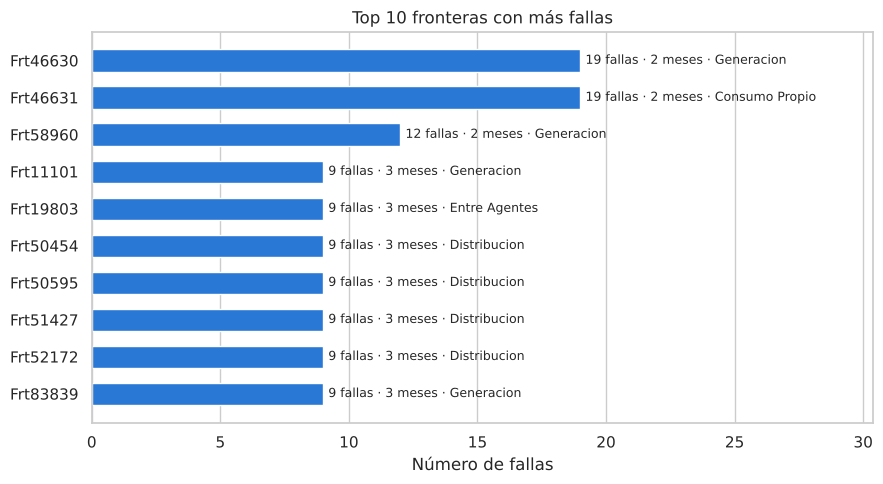

,Fallas,Meses,Tipo_Frontera
Frontera,,,
Frt46630,19,2,Generacion
Frt46631,19,2,Consumo Propio
Frt58960,12,2,Generacion
Frt11101,9,3,Generacion
Frt19803,9,3,Entre Agentes
Frt50454,9,3,Distribucion
Frt50595,9,3,Distribucion
Frt51427,9,3,Distribucion
Frt52172,9,3,Distribucion


In [14]:
por_frontera = df.groupby("Frontera").agg(
    Fallas=("Mes", "size"),
    Meses=("Mes", "nunique"),
    Tipo_Frontera=("Tipo_Frontera", "first"),
).sort_values(["Fallas", "Meses"], ascending=False)

print("Fronteras distintas:", len(por_frontera))
print("Promedio de fallas por frontera:", round(por_frontera["Fallas"].mean(), 2))
print("Fronteras que aparecen en 3 o más meses:", (por_frontera["Meses"] >= 3).sum())

top10 = por_frontera.head(10).iloc[::-1]
plt.figure(figsize=(9, 5))
plt.barh(top10.index, top10["Fallas"], color=azul, height=0.6)
for i, (f, m, t) in enumerate(zip(top10["Fallas"], top10["Meses"], top10["Tipo_Frontera"])):
    plt.text(f + 0.2, i, f"{f} fallas · {m} meses · {t}", va="center", fontsize=9)
plt.xlim(0, top10["Fallas"].max() * 1.6)
plt.xlabel("Número de fallas")
plt.title("Top 10 fronteras con más fallas")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

por_frontera.head(10)

Cada frontera acumula en promedio **4.2 fallas**, con un mínimo de 2. Las fronteras **Frt46631** (Consumo Propio) y **Frt46630** (Generación)
tienen **19 fallas cada una**, muy por encima del resto, y probablemente corresponden a la misma instalación. El top 10 está formado solo por
fronteras de **generación, distribución, consumo propio y entre agentes**, todas en PN.

## Antigüedad de las fallas al publicarse

Días entre la **fecha de reporte** de la falla y el **fin del mes** en que se publica la decisión.

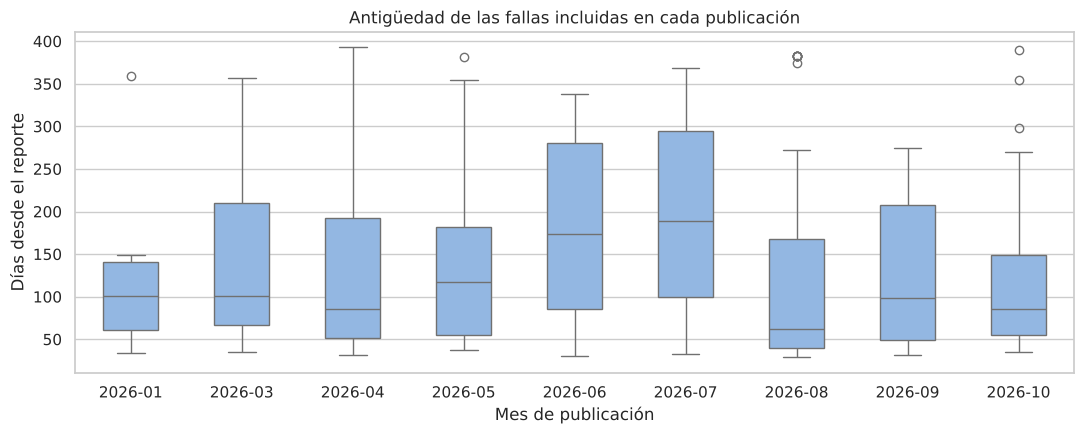

,count,min,50%,mean,max
Mes,,,,,
2026-01,9.0,34.0,101.0,125.0,359.0
2026-03,64.0,35.0,101.0,136.0,357.0
2026-04,29.0,31.0,86.0,129.0,393.0
2026-05,33.0,37.0,117.0,137.0,382.0
2026-06,89.0,30.0,174.0,177.0,338.0
2026-07,78.0,33.0,189.0,191.0,369.0
2026-08,57.0,29.0,62.0,122.0,383.0
2026-09,21.0,32.0,99.0,127.0,275.0
2026-10,44.0,35.0,86.0,115.0,390.0


In [15]:
df["Dias_Hasta_Publicacion"] = (df["Mes"].dt.end_time.dt.normalize() - df["Fecha_Reporte"].dt.normalize()).dt.days

plt.figure(figsize=(11, 4.5))
sns.boxplot(x=df["Mes"].astype(str), y=df["Dias_Hasta_Publicacion"], color="#86b6ef", width=0.5)
plt.xlabel("Mes de publicación")
plt.ylabel("Días desde el reporte")
plt.title("Antigüedad de las fallas incluidas en cada publicación")
plt.tight_layout()
plt.show()

df.groupby(df["Mes"].astype(str))["Dias_Hasta_Publicacion"].describe()[["count", "min", "50%", "mean", "max"]].round(0)

Ninguna falla se publica antes de **~30 días** de reportada y algunas llegan a tener más de un año (hasta 393 días), lo que indica que la
publicación recoge fallas acumuladas en una **ventana de 12 meses**. En **junio y julio** las fallas son más antiguas (mediana de 174 y 189 días),
mientras que en **agosto** son las más recientes (mediana 62 días).

## Referencia: histórico 2022

In [16]:
historico[["Frtid", "Cantidad de Fallas", "Tipo de Frontera", historico.columns[6], "Nombre Frontera"]]

,Frtid,Cantidad de Fallas,Tipo de Frontera,Está en Plan de Normalización,Nombre Frontera
0,Frt04385,3,No Regulado,No,OLIMPICA S.A SAO 640
1,Frt28246,3,No Regulado,No,BRIGADA 9-EJERCITO NACIONAL
2,Frt10947,3,Consumo Auxiliar,No,CONSUMOS AUX UBALA TA
3,Frt25068,4,Consumo Propio,Sí,COELLO
4,Frt24818,3,Generacion,Sí,COELLO
5,Frt47315,3,Generacion,No,COMERCIALIZADORA INTERNACIONAL CI JEANS
6,Frt46293,3,Generacion,Sí,PARQUE EOLICO GUAJIRA I
7,Frt44436,3,Generacion,Sí,AGPE Alvaro Hoyos
8,Frt41727,6,Generacion,Sí,AGPE AGRODEX
9,Frt38124,3,Generacion,No,Termoyopal Linea 2


La hoja `Historico_2022` es **una sola publicación** de 2022 con **10 fronteras** (3 o 4 fallas cada una). No es comparable con los 9 meses acumulados de 2026 (100 fronteras), así que se deja solo como referencia del formato y del tipo de fronteras publicadas.

## Conclusiones

### Comportamiento mensual
- El volumen de fallas no es estable: hay picos en **marzo (64)** y en **junio–julio (89 y 78)**, y un mínimo en **septiembre (21)**.
- Falta el mes de **febrero**, por lo que marzo podría incluir fallas acumuladas de ese mes.

### Cancelación vs Plan de Normalización
- Contando por frontera, **70 de 100 se cancelaron y 30 entraron a PN** (por falla: 55% y 45%).
- La decisión depende solo del **tipo de frontera**, como establece el Anexo 11 del Código de Medida (CREG 033 de 2019): Regulado/No Regulado se cancelan; Generación, Distribución, Consumo Propio y Entre Agentes entran a PN.
- El salto de PN en junio–julio se explica por la entrada de muchas fronteras de **generación y consumo propio**.

### Tipos de falla
- La **falla de dispositivos de interfaz de comunicación** es el principal problema: 128 fallas (30%) en **46 de las 100 fronteras**, y vuelve a subir en octubre (24, cerca del máximo de junio, 27).
- **28 de las 70 fronteras canceladas** tenían fallas de comunicación: para un usuario regulado, un módem caído puede terminar en la cancelación de la frontera, porque el art. 36 de la CREG 038 de 2014 la cuenta igual que una falla del medidor.
- Las fallas por **no envío de lectura** también son importantes (25%), y casi todas terminan en PN.

### Fronteras
- **100 fronteras** con fallas; unas pocas (Frt46631, Frt46630, Frt58960) concentran muchas fallas.
- Solo en junio y julio aparecen fronteras que ya se habían publicado antes.

## Recomendaciones

- **Atender las comunicaciones**: revisar módems y dispositivos de interfaz, que son la falla más común y en crecimiento.
- **Hacer seguimiento a fronteras críticas**: priorizar las del top 10, en especial Frt46631 y Frt46630, que tienen 19 fallas cada una.
- **Monitorear las fronteras en PN**: como se repiten entre meses, conviene verificar que los planes de normalización se estén cumpliendo.
- **Completar la información**: conseguir el archivo de **2026-02** para tener la serie completa del año.